# Recurrent models: closed loops and sequences

A dynamic system has a **state**: its position, its speed, a temperature. Each
step computes the next state from the current one and the inputs, and the next
step starts from it. A model of such a system can be used in two ways:

- **one step ahead**: the current state is read from the measurements at every
  step - simple, but the model never sees its own errors;
- **closed loop**: the state the model computed is **fed back** as the state of
  the next step, over a whole trajectory - a simulator. Trained this way, on the
  simulation error, the model learns to stay right over a horizon.

*nnodely* closes the loop in two ways:

- `ModelyLoop` - the model is written **one step at a time**: a state is an
  `Input` fed back with its next value, `x.feedback(next_x)`;
- `Loop` - an existing one-step model is **rolled out** over sequences, inside
  a bigger model.

Both add a **sequence axis** `S` to the streams: the steps of the trajectory.

In [1]:
import os

# Pick the Keras backend before nnodely (or Keras) is imported:
# "tensorflow" (the default), "torch" or "jax".
os.environ.setdefault("KERAS_BACKEND", "tensorflow")

import keras
import matplotlib.pyplot as plt
import numpy as np

from nnodely import (
    Buffer,
    DataLoader,
    Input,
    Linear,
    Loop,
    Modely,
    ModelyLoop,
    Output,
    Parameter,
    set_seed,
)

set_seed(0)

## The system

A mass on a spring with a damper, pushed by a force `F`:

$$\dot v = (F - k\,x - c\,v)/m, \qquad \dot x = v$$

simulated with a step `dt`, with `k = 2` and `c = 0.5` - the values to find.

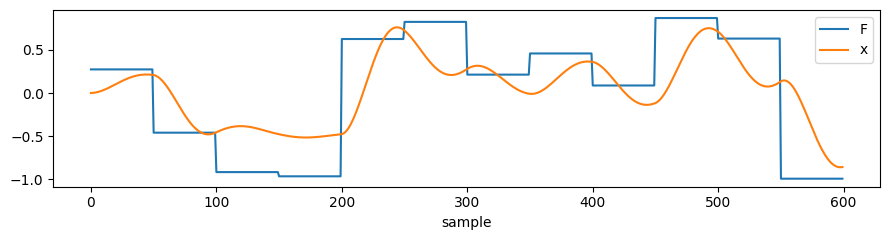

In [2]:
dt, m = 0.05, 1.0
rng = np.random.default_rng(0)
F_data = np.repeat(rng.uniform(-1.0, 1.0, 60), 50)  # 3000 samples
X, V = np.zeros(3000), np.zeros(3000)
for i in range(2999):
    V[i + 1] = V[i] + dt * (F_data[i] - 2.0 * X[i] - 0.5 * V[i]) / m
    X[i + 1] = X[i] + dt * V[i + 1]

plt.figure(figsize=(9, 2.5))
plt.plot(F_data[:600], label="F")
plt.plot(X[:600], label="x")
plt.legend()
plt.xlabel("sample")
plt.tight_layout()

## `ModelyLoop`: a model written one step at a time

Inside the step, the states `x` and `v` are inputs of one sample, `tw=1`: their
values at the end of the previous step. `feedback(stream)` says which stream is
their value at the end of this step - the one the next step starts from - and
returns it. The equations are written as they are:

In [3]:
F, x, v = Input("F", tw=1), Input("x", tw=1), Input("v", tw=1)
k, c = Parameter("k", value=1.0), Parameter("c", value=1.0)  # wrong guesses

v_next = v.feedback(v + dt * (F - k * x - c * v) / m)
x_next = x.feedback(x + dt * v_next)

msd = ModelyLoop("msd", inputs=[F, x, v], outputs=[Output("x_next", x_next)])
msd.inputs

┏━━━━━━━┳━━━━━━━┳━━━━━━━━┳━━━━┳━━━━━━┳━━━━━━━━━━┳━━━━━━━━━━━━━━━┳━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┓
┃ index ┃ input ┃ seq    ┃ tw ┃ dim  ┃ declared ┃ fed back with ┃ data     ┃ starts from                  ┃
┡━━━━━━━╇━━━━━━━╇━━━━━━━━╇━━━━╇━━━━━━╇━━━━━━━━━━╇━━━━━━━━━━━━━━━╇━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┩
│ 0     │ x     │ (dyn,) │ 1  │ (1,) │ yes      │ Add11         │ optional │ its data, first step, else 0 │
│ 1     │ v     │ (dyn,) │ 1  │ (1,) │ yes      │ Add9          │ optional │ its data, first step, else 0 │
│ 2     │ F     │ (dyn,) │ 1  │ (1,) │ yes      │ -             │ required │ -                            │
└───────┴───────┴────────┴────┴──────┴──────────┴───────────────┴──────────┴──────────────────────────────┘

The table shows how each input is fed:

- `F` is read from data at every step;
- `x` and `v` are fed back with their next value. Listed among the inputs, they
  **start from their data** at the first step of each trajectory - `optional`:
  left out of the data, they start from zero;
- every input carries the trajectory as a new **sequence axis**, `seq=(dyn,)`:
  as many steps as the data holds.

Every output is a trajectory: element `k` is computed at step `k`.

### Training on trajectories

The data is cut into trajectories of `H` steps with `seq_length=H`. The target
is the state **one step ahead** of the data the trajectory starts from:
`x_next` at step `k` is the state at `k + 1`.

In [4]:
msd.minimize("trajectory", "x_next", Input("x_meas", tw=1))
msd.build()

data = {"F": F_data[:-1], "x": X[:-1], "v": V[:-1], "x_meas": X[1:]}
trajectories = DataLoader(msd, source=data, seq_length=50, step=10)
print(
    len(trajectories), "trajectories of", trajectories.as_dict()["F"].shape[1], "steps"
)

msd.train(trajectories, epochs=30, batch_size=32, lr=5e-2, printer=None)
print("k =", k.value_numpy, " c =", c.value_numpy)

295 trajectories of 50 steps
k = [2.]  c = [0.49999994]


The model only saw the measured state at the first step of each trajectory:
the rest it simulated. Run on the whole recording - `seq_length="full"`, one
trajectory of every step - it is a simulator of the system:

trajectory shape: (1, 2999, 1, 1)


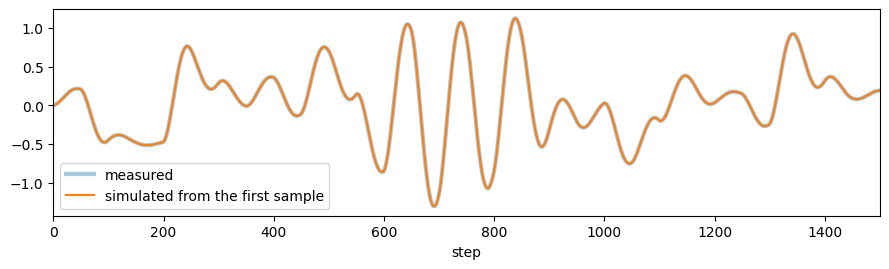

In [5]:
whole = DataLoader(msd, source=data, seq_length="full").as_dict()
simulated = keras.ops.convert_to_numpy(msd(whole)["x_next"]).ravel()
print("trajectory shape:", keras.ops.convert_to_numpy(msd(whole)["x_next"]).shape)

plt.figure(figsize=(9, 2.8))
plt.plot(X[1:], lw=3, alpha=0.4, label="measured")
plt.plot(simulated, label="simulated from the first sample")
plt.xlim(0, 1500)
plt.legend()
plt.xlabel("step")
plt.tight_layout()

The trajectory is `(batch, steps, T, D)`: one sample, 2999 steps, each a window
of one sample of one feature - the sequence axis `S` sits between the batch
and the window.

A state left out of the data starts from zero - the `optional` of the table:

In [6]:
from_rest = {"F": whole["F"]}  # x and v left out: zero
simulated_from_rest = keras.ops.convert_to_numpy(msd(from_rest)["x_next"]).ravel()
print(simulated_from_rest[:5].round(5))

[0.00068 0.00203 0.00402 0.00663 0.00982]


## `Loop`: rolling out a one-step model

`Loop` takes a model of **one step** - a body - and repeats it inside a bigger
model. Its inputs become sequences: a stream with one more sequence axis than
the body's input is read one step at a time.

Here the body is a linear state-space step, $s_{k+1} = A\,s_k + B\,F_k$, with
the state `s = [x, v]` and `A`, `B` learned by two `Linear` layers. They start
from a model that does nothing: `A` the identity - the state stays as it is -
and `B` zero. Rolled out over many steps, random weights can make the
trajectories explode, or settle the training in a poor solution: start a
simulator from a stable guess.

The body feeds nothing back itself, so `feedback=` says which output becomes
which input at the next step, and `init=` where the state starts:

In [7]:
state = Input("state", dim=2, tw=1)
force = Input("force", tw=1)
next_state = Output(
    "next_state",
    Linear(features=2, bias=False, kernel="identity", name="A")([state])
    + Linear(features=2, bias=False, kernel="zeros", name="B")([force]),
)
body = Modely("step", inputs=[state, force], outputs=[next_state])

H = 40
seed = Input("seed", dim=2, seq=H, tw=1)  # its first step is the initial state
forces = Input("forces", seq=H, tw=1)  # one force per step
rollout = Loop(f=body, feedback={state: next_state}, init={state: seed})(
    {force: forces}
)
print("one step: ", next_state.shape)
print("rollout:  ", rollout.shape)

one step:  Shape(S=(), T=1, D=(2,))
rollout:   Shape(S=(40,), T=1, D=(2,))


The rollout collects every step of the body's output along a new sequence axis:
`S=(40,)`. The outer model is an ordinary `Modely`, trained on trajectories of
`H` steps read from data with `seq=H`:

In [8]:
simulator = Modely(
    "simulator", inputs=[seed, forces], outputs=[Output("trajectory", rollout)]
)
simulator.minimize("trajectory", "trajectory", Input("target", dim=2, seq=H, tw=1))
simulator.build()

S = np.stack([X, V], axis=1)  # (time, 2)
loop_data = DataLoader(
    simulator, source={"seed": S[:-1], "forces": F_data[:-1], "target": S[1:]}, step=5
)
simulator.train(loop_data, epochs=40, batch_size=32, lr=1e-2, printer=None)

A_true = np.array(
    [[1 - dt**2 * 2.0 / m, dt - dt**2 * 0.5 / m], [-dt * 2.0 / m, 1 - dt * 0.5 / m]]
)
A_learned = simulator.parameters[
    "A_kernel"
].value_numpy.T  # Linear computes s @ W: A = W^T
print("A learned:\n", A_learned.round(4))
print("A true:\n", A_true.round(4))
print(
    "B learned:",
    simulator.parameters["B_kernel"].value_numpy.ravel().round(4),
    " true:",
    np.round([dt**2 / m, dt / m], 4),
)

A learned:
 [[ 0.995   0.0488]
 [-0.1     0.975 ]]
A true:
 [[ 0.995   0.0488]
 [-0.1     0.975 ]]
B learned: [0.0025 0.05  ]  true: [0.0025 0.05  ]


### When things happen

At step `k` the body sees the state $s_k$ - $s_0$ from `init` - and the inputs
$u_k$; its output becomes $s_{k+1}$. The collected trajectory is therefore
$s_1 \dots s_H$: one step ahead of the seed window. That is why the target is
the data shifted by one, `S[1:]`, against the seed `S[:-1]`.

### Options

| Option | Effect |
|---|---|
| `init={state: stream}` | the initial state: a stream with the rollout as one more sequence axis (its first step is read), a stream of the state's shape, or a number; zero when left out |
| `feedback={input: output}` | which output feeds which input, for a body that does not `feedback()` itself |
| `length=H` | the horizon, when no input carries it |
| `collect=False` | return only the last step, not the trajectory |
| `seq=-1` | inputs of any length: the rollout follows the data (`seq_length=` in the `DataLoader`) |

A body that feeds its own states back with `x.feedback(...)` needs no
`feedback=`: the `Loop` finds them. A `ModelyLoop` is exactly a `Loop` over its
step, whose sequence inputs it creates by itself.

## Windows of computed signals: `Buffer`

A step reads the past of a signal **computed** inside the loop - the last
commands of a controller, say - with `Buffer(tw=n)`: the last `n` values of the
signal, the current one included, fed back from step to step:

In [9]:
u = Input("u", tw=1)
window = Buffer(tw=3)(u)
buffered = ModelyLoop(
    "buffered", inputs=[u], outputs=[Output("window", window)]
).build()
steps = np.arange(1.0, 5.0).reshape(1, 4, 1, 1)  # u = 1, 2, 3, 4
print(keras.ops.convert_to_numpy(buffered(steps)["window"])[0, :, :, 0])

[[0. 0. 1.]
 [0. 1. 2.]
 [1. 2. 3.]
 [2. 3. 4.]]


Each step reads the last 3 values of `u`, zeros before the start (or the
`init=` of the `Buffer`). Stateful layers - `Buffer`, and `Integrate` and
`Derivative` of [Calculus](11_calculus.ipynb) - keep their past in hidden inputs
that the `ModelyLoop` or `Loop` feeds back with the other states.

## Summary

| Task | Code |
|---|---|
| A state | `x = Input("x", tw=1)`, `x_next = x.feedback(next_value)` |
| A model written step by step | `ModelyLoop("name", inputs=[...], outputs=[...])` |
| Where states start | listed in `inputs`: their data at the first step; else zero |
| Its data | `DataLoader(model, source, seq_length=H)` or `"full"`; target one step ahead |
| Roll out a one-step model | `Loop(f=body, feedback={...}, init={...})({input: sequence})` |
| Sequence inputs | `Input("u", seq=H, tw=1)`, `seq=-1` for any length |
| The trajectory | a new sequence axis: `S=(H,)`, arrays `(batch, H, T, *D)` |
| The past of a computed signal | `Buffer(tw=n)(signal)` |

Next: [Calculus](11_calculus.ipynb).